In [1]:
# Run this and then restart the kernel at the start of each session to install
# 'teotil3' in development mode
# !pip install -e /home/jovyan/teotil3/

In [2]:
import os
import matplotlib.pyplot as plt

import geopandas as gpd
import nivapy3 as nivapy
import numpy as np
import pandas as pd
import teotil3 as teo
from osgeo import gdal
from rasterstats import zonal_stats
from sqlalchemy import create_engine, text
from tqdm.notebook import tqdm

gdal.UseExceptions()

In [3]:
eng = nivapy.da.connect_postgis()

Connection successful.


# Annual time series, or static derived from annual

 * Estimates of annual atmospheric deposition of nitrogen (DIN) and non-marine sulphur (S*) from 1970 to present (kg/ha/yr) (EMEP)
 * Point discharges DIN, TOTN, TOTP and TOC from industry and "large" wastewater sites (> 50 p.e.). Averaged for the period 2017 - "end_date" (user-specified)  from 2013 to 2022 (kg) (TEOTIL3). Averaged.

**Future improvements/to do:**
- EMEP data:
    - Use AR50 to average forest and seminatural deposition values per catchment, rather than grid-average values.
    - Code is inefficient at the moment (does EMEP grid intersection with the catchments every year with EMEP data; could just do for two unique grids present)
- TEOTIL3 point inputs:
    - Currently only save average for period 2017-2024. For large WWTWs, the change in method in 2017 didn't affect them, so worth exploring interannual variability.
    - QC is a bit hardcoded to mostly be for TOC


In [4]:
# Catchment boundaries
cat_fpath = r"/home/jovyan/shared/common/norsink/spatial/monitored_chem_catchments/catchments_vm-rivs-quant-oc_v3-full.gpkg"
cat_id_col = "site_code"

# Output folder (result csvs added here)
catchment_set = "monitored-oc-catchs"  # for filenaming
out_folder = r"/home/jovyan/shared/common/norsink/vm_catchments_data"

# Read catchment boundaries

In [5]:
# Read catchments
cat_gdf = gpd.read_file(cat_fpath)

# cat_gdf = cat_gdf[:50].copy()
cat_gdf.head()

,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2,geometry
0,001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,2011,2025,14.0,14,1.00,1008.505005,"POLYGON ((306680 6664180, 306760 6664180, 3067..."
1,001-119929,11.654461,59.472300,119929,Nedstrøms Bommen RA,2011,2025,14.0,14,1.00,1009.065359,"POLYGON ((306680 6664180, 306760 6664180, 3067..."
2,001-30653,11.437438,59.070299,30653,YSTE YSTEHEDEBEKKEN,1987,1987,1.0,4,4.00,6.702626,"POLYGON ((298520 6555300, 298640 6555300, 2986..."
3,001-30683,11.295421,59.121185,30683,"Unnebergbekken, UNNE",1987,2016,29.1,5,0.17,15.372746,"POLYGON ((290660 6567260, 290680 6567260, 2906..."
4,001-30687,11.528412,58.987892,30687,ØRB2 ØRBEKKEN,1991,1991,1.0,4,4.00,42.290760,"POLYGON ((305560 6548480, 305560 6548500, 3055..."


# Atmospheric deposition

M. Posch provided a temporally consistent EMEP reanalysis from 1880 to 2010 (5-yearly), with predictions for 2020 and 2030. The raw spatial resolution was the EMEP grid, 0.5' x 0.25', i.e. pretty coarse (50 x 25 km squares'ish), but resampled by James Sample for critical loads work. These data are available in the Critical Loads sql database. Data are available for three vegetation classes: 1-grid average, 2-forested, 3-seminatural. The data are total deposition (i.e. wet + dry). Parameter_ids are 1-n_oxidised, 2-n-reduced, 3-sulphur, 4-nonmarine sulphur.

Here, we average over grid squares and then linearly interpolate to get annual values per catchment.
For simplicity, we pick vegetation class 1 (land cover average), which should give a coarse approximation of spatial variability. Future improvement, if deposition is a really important feature, would be to use catchment-specific land cover data (AR50) rather than the pre-calculated grid averages.

**To do:** efficiency saving possible by not doing the grid intersection with the catchments every year, only for the years when it changes (i.e. once for the period 1980-2010, again for the period 2020-2030)

## Functions for extracting data

In [6]:
def extract_n_deposition_as_gdf(series_id, eng):
    """Extracts DIN deposition (oxidised + reduced N) for the specified series
    as a geodataframe.

    Args:
        series_id: Int. Series ID of interest
        eng:       Obj. Active database connection object

    Returns:
        GeoDataFrame.
    """
    assert isinstance(series_id, int), "'year' must be an integer."

    param_dict = {"series_id": series_id}
    sql = (
        "SELECT ST_Multi(ST_Transform(b.geom, 32633)) AS geom, "
        "  a.cell_id, "
        "  ROUND(a.n_dep) AS ndep_mgpm2pyr "
        "FROM (SELECT cell_id, SUM(value) as n_dep "
        "      FROM deposition.dep_values_emep_grid "
        "      WHERE param_id IN (1, 2) "
        "      AND veg_class_id = 1 "
        "      AND series_id = :series_id "
        "      GROUP BY cell_id) AS a, "
        "deposition.dep_grid_emep AS b "
        "WHERE a.cell_id = b.cell_id"
    )
    sql = text(sql)
    gdf = gpd.read_postgis(sql, eng, params=param_dict)

    return gdf


def extract_s_deposition_as_gdf(series_id, eng):
    """Extracts non-marine S deposition for the specified series
    as a geodataframe.

    Args:
        series_id: Int. Series ID of interest
        eng:       Obj. Active database connection object

    Returns:
        GeoDataFrame.
    """
    assert isinstance(series_id, int), "'year' must be an integer."

    param_dict = {"series_id": series_id}
    sql = (
        "SELECT ST_Multi(ST_Transform(b.geom, 32633)) AS geom, "
        "  a.cell_id, "
        "  ROUND(a.s_dep) AS sdep_mgpm2pyr "
        "FROM (SELECT cell_id, SUM(value) as s_dep "
        "      FROM deposition.dep_values_emep_grid "
        "      WHERE param_id = 4 "
        "      AND veg_class_id = 1 "
        "      AND series_id = :series_id "
        "      GROUP BY cell_id) AS a, "
        "deposition.dep_grid_emep AS b "
        "WHERE a.cell_id = b.cell_id"
    )
    sql = text(sql)
    gdf = gpd.read_postgis(sql, eng, params=param_dict)

    return gdf


def extract_dep_as_gdf(series_id, eng):
    """
    Extract both DIN and nmSO4-S at the same time
    """
    sql = text(
        """
        SELECT
            ST_Multi(ST_Transform(b.geom, 32633)) AS geom,
            a.cell_id,
            ROUND(a.n_dep) AS ndep_mgpm2pyr,
            ROUND(a.s_dep) AS sdep_mgpm2pyr
        FROM
        (
            SELECT
                cell_id,

                SUM(
                    CASE
                        WHEN param_id IN (1,2)
                        THEN value
                        ELSE 0
                    END
                ) AS n_dep,

                SUM(
                    CASE
                        WHEN param_id = 4
                        THEN value
                        ELSE 0
                    END
                ) AS s_dep

            FROM deposition.dep_values_emep_grid
            WHERE veg_class_id = 1
            AND series_id = :series_id
            AND param_id IN (1,2,4)
            GROUP BY cell_id
        ) a
        JOIN deposition.dep_grid_emep b
            ON a.cell_id = b.cell_id
        """
    )

    return gpd.read_postgis(
        sql,
        eng,
        params={"series_id": series_id},
    )


## Get data

In [7]:
# Get list of available EMEP deposition series
st_yr, end_yr = 1980, 2030

# Get list of 'standard' EMEP series from db
sql = text(
    "SELECT * FROM deposition.dep_series_defs "
    "WHERE grid = 'emep' "
    "AND short_name NOT LIKE '%b'"
)
dep_series_df = pd.read_sql(sql, eng)

# Find series within period of interest
dep_series_df["year"] = dep_series_df["name"].str.split(" ", n=1, expand=True)[1].astype(int)
dep_series_df = dep_series_df.query("@st_yr <= year <= @end_yr")
dep_series_df.sort_values("year", ascending=True, inplace=True)

# Show series already in database
with pd.option_context("display.max_colwidth", None):
    display(dep_series_df)

,series_id,name,short_name,grid,description,year
20,51,EMEP 1980,emep1980,emep,1980 data based on the EMEP 0.50x0.25 degree grid. Includes values for different vegetation classes,1980
21,52,EMEP 1985,emep1985,emep,1985 data based on the EMEP 0.50x0.25 degree grid. Includes values for different vegetation classes,1985
22,53,EMEP 1990,emep1990,emep,1990 data based on the EMEP 0.50x0.25 degree grid. Includes values for different vegetation classes,1990
23,54,EMEP 1995,emep1995,emep,1995 data based on the EMEP 0.50x0.25 degree grid. Includes values for different vegetation classes,1995
24,55,EMEP 2000,emep2000,emep,2000 data based on the EMEP 0.50x0.25 degree grid. Includes values for different vegetation classes,2000
25,56,EMEP 2005,emep2005,emep,2005 data based on the EMEP 0.50x0.25 degree grid. Includes values for different vegetation classes,2005
26,57,EMEP 2010,emep2010,emep,2010 data based on the EMEP 0.50x0.25 degree grid. Includes values for different vegetation classes,2010
27,58,EMEP 2020,emep2020,emep,2020 data based on the EMEP 0.50x0.25 degree grid. Includes values for different vegetation classes,2020
28,59,EMEP 2030,emep2030,emep,2030 data based on the EMEP 0.50x0.25 degree grid. Includes values for different vegetation classes,2030


In [8]:
# # Explore how the emep grid changes over time. See that it's different for 2020 and 2030
# # So can't just do one intersection with the catchment boundaries? Instead, one per year?

# for series_id in dep_series_df["series_id"]:
#     gdf = extract_n_deposition_as_gdf(int(series_id), eng)

#     print(
#         series_id,
#         len(gdf),
#         gdf["cell_id"].nunique(),
#     )

# hist = extract_n_deposition_as_gdf(
#     int(dep_series_df.iloc[0]["series_id"]),
#     eng,
# )[["cell_id"]]

# future = extract_n_deposition_as_gdf(
#     int(dep_series_df.loc[dep_series_df["year"] == 2020,
#                           "series_id"].iloc[0]),
#     eng,
# )[["cell_id"]]

# hist_ids = set(hist["cell_id"])
# future_ids = set(future["cell_id"])

# print("Only in future:", len(future_ids - hist_ids))
# print("Only in historic:", len(hist_ids - future_ids))

# # gdf2 = extract_n_deposition_as_gdf(
# #     int(dep_series_df.iloc[-1]["series_id"]),
# #     eng,
# # )
# # gdf2

In [9]:
# Extract emep data and average over catchment polygons

# Keep only catchment ID and geometry, then reproject to an equal-area CRS
# so that polygon areas are calculated correctly.
dep_cat_gdf = cat_gdf[[cat_id_col, "geometry"]].copy()
dep_cat_gdf_cea = dep_cat_gdf.to_crs({"proj": "cea"})

# Store annual results for all deposition series
df_list = []

for _, row in tqdm(
    dep_series_df.iterrows(),
    total=len(dep_series_df),
    desc="Processing deposition series",
):
    series_id = int(row["series_id"])
    year = int(row["year"])

    # Extract gridded N and S deposition data for this year
    dep_gdf = extract_dep_as_gdf(series_id, eng)
    dep_gdf_cea = dep_gdf.to_crs({"proj": "cea"})

    # Intersect catchments with EMEP grid cells. Each resulting polygon
    # represents the overlap between a catchment and a deposition grid cell.
    int_gdf = gpd.overlay(
        dep_cat_gdf_cea,
        dep_gdf_cea,
        how="intersection",
        keep_geom_type=True,
    )

    # Area of each overlap polygon (km2)
    int_gdf["area_km2"] = int_gdf.geometry.area / 1e6

    # Area-weight deposition values so that catchment means can be
    # calculated from partial grid-cell overlaps.
    int_gdf["n_weighted"] = (
        int_gdf["area_km2"] * int_gdf["ndep_mgpm2pyr"]
    )

    int_gdf["s_weighted"] = (
        int_gdf["area_km2"] * int_gdf["sdep_mgpm2pyr"]
    )

    # Sum overlap areas and weighted deposition values by catchment
    ag_df = (
        int_gdf
        .groupby(cat_id_col)
        .sum(numeric_only=True)
    )

    # Calculate area-weighted mean deposition for each catchment
    ag_df["emep_din_kghayr"] = (
        ag_df["n_weighted"] / ag_df["area_km2"]
    ) * 0.01

    ag_df["emep_nms_kghayr"] = (
        ag_df["s_weighted"] / ag_df["area_km2"]
    ) * 0.01

    # Keep only final outputs and add the corresponding year
    ag_df = ag_df[["emep_din_kghayr", "emep_nms_kghayr"]]
    ag_df["year"] = year

    df_list.append(ag_df.reset_index())

# Combine all years into a single long-format dataframe
dep_df = pd.concat(df_list, ignore_index=True)

dep_df

Processing deposition series:   0%|          | 0/9 [00:00<?, ?it/s]

,site_code,emep_din_kghayr,emep_nms_kghayr,year
0,001-119928,7.400665,14.672134,1980
1,001-119929,7.401031,14.673049,1980
2,001-30653,7.570000,15.970000,1980
3,001-30683,7.570000,15.970000,1980
4,001-30687,8.865873,17.090924,1980
...,...,...,...,...
76333,313-99151,3.165719,0.833537,2030
76334,314-46646,3.420000,1.040000,2030
76335,314-48074,3.332201,0.932690,2030
76336,314-62046,3.627539,1.040000,2030


In [10]:
# Some manual QC (looks about right, haven't done thorough check)
# Check for one catchment
test_gdf = int_gdf.loc[
    int_gdf[cat_id_col] == "001-119928",
    ["area_km2", "ndep_mgpm2pyr", "sdep_mgpm2pyr"]
]

display(test_gdf)

sum(int_gdf['sdep_mgpm2pyr'] * int_gdf['area_km2']) / sum(int_gdf['area_km2'])

# Check for area leak
cat_area = dep_cat_gdf_cea.geometry.area.sum() / 1e6
int_area = int_gdf.groupby(cat_id_col)["area_km2"].sum()

print(cat_area, int_area.sum())

,area_km2,ndep_mgpm2pyr,sdep_mgpm2pyr
0,9.367193,364.0,104.0
1,76.015387,352.0,105.0
2,279.594884,342.0,104.0
3,230.007949,341.0,103.0
4,380.852986,333.0,93.0
5,0.253807,309.0,93.0
6,32.412799,331.0,86.0


3147212.9714423115 3147212.9714423157


## Interpolate to annual & save

In [11]:
# Interpolate deposition data to a complete annual time series for each catchment.
# Each group contains EMEP deposition estimates for one catchment.
annual_dep_df = []
yr_li = range(st_yr, end_yr + 1)

for site_id, grp in dep_df.groupby(cat_id_col):

    # Use year as the index and ensure records are in chronological order
    grp = grp.set_index("year").sort_index()

    # Add rows for all years in the requested period. Years without
    # deposition estimates are filled with NaN and will be interpolated.
    grp = grp.reindex(yr_li)

    # Linearly interpolate N and S deposition between available EMEP years
    grp["emep_din_kghayr"] = grp["emep_din_kghayr"].interpolate().round(2)
    grp["emep_nms_kghayr"] = grp["emep_nms_kghayr"].interpolate().round(2)

    # Restore catchment ID and year as regular columns
    grp[cat_id_col] = site_id
    grp["year"] = grp.index

    annual_dep_df.append(grp.reset_index(drop=True))

# Combine all catchment-specific annual time series into a single dataframe
annual_dep_df = pd.concat(
    annual_dep_df,
    ignore_index=True,
)


# Check no NaNs left
assert pd.isna(annual_dep_df).sum().sum() == 0

# Save
fname_suffix = "annual_emep_nsdep"
out_fpath = os.path.join(out_folder, f"{catchment_set}_{fname_suffix}.csv")
annual_dep_df.to_csv(out_fpath, index=False)

annual_dep_df

,site_code,emep_din_kghayr,emep_nms_kghayr,year
0,001-119928,7.40,14.67,1980
1,001-119928,7.53,14.27,1981
2,001-119928,7.66,13.87,1982
3,001-119928,7.79,13.47,1983
4,001-119928,7.92,13.07,1984
...,...,...,...,...
432577,314-89994,3.41,0.97,2026
432578,314-89994,3.39,0.96,2027
432579,314-89994,3.37,0.95,2028
432580,314-89994,3.35,0.94,2029


## QC

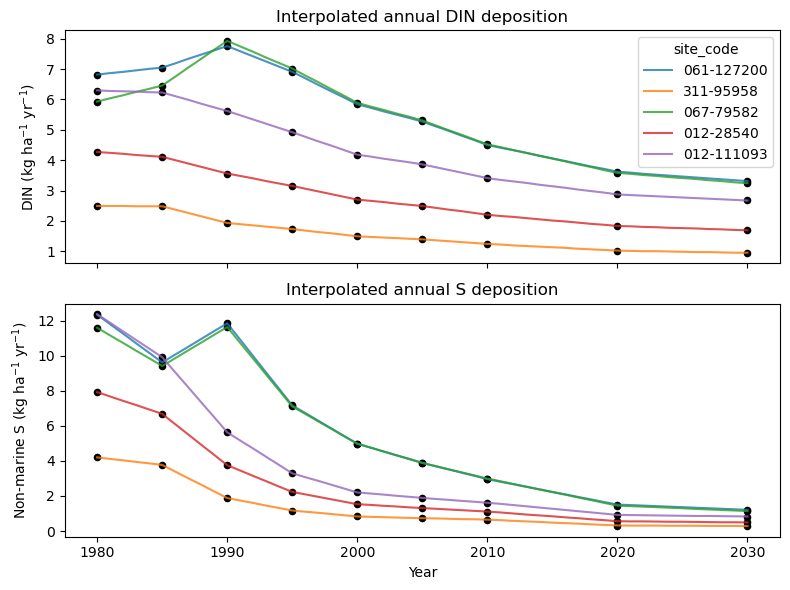

In [12]:
# Quick QC plots

# Select a few catchments to inspect
n_sites = 5
plot_sites = annual_dep_df[cat_id_col].drop_duplicates().sample(
    n=min(n_sites, annual_dep_df[cat_id_col].nunique()),
    random_state=20,
)

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(8, 6),
    sharex=True,
)

for site_id in plot_sites:
    annual_site = annual_dep_df.query(f"{cat_id_col} == @site_id")
    orig_site = dep_df.query(f"{cat_id_col} == @site_id")

    # DIN
    axes[0].plot(
        annual_site["year"],
        annual_site["emep_din_kghayr"],
        alpha=0.8,
        label=site_id,
    )
    axes[0].scatter(
        orig_site["year"],
        orig_site["emep_din_kghayr"],
        color="k",
        s=20,
    )

    # Non-marine sulphur
    axes[1].plot(
        annual_site["year"],
        annual_site["emep_nms_kghayr"],
        alpha=0.8,
        label=site_id,
    )
    axes[1].scatter(
        orig_site["year"],
        orig_site["emep_nms_kghayr"],
        color="k",
        s=20,
    )

axes[0].set_ylabel("DIN (kg ha$^{-1}$ yr$^{-1}$)")
axes[0].set_title("Interpolated annual DIN deposition")

axes[1].set_ylabel("Non-marine S (kg ha$^{-1}$ yr$^{-1}$)")
axes[1].set_xlabel("Year")
axes[1].set_title("Interpolated annual S deposition")

axes[0].legend(title=cat_id_col)

plt.tight_layout()
plt.show()

# Point inputs

From large wastewater and industry. From TEOTIL3.

## Get annual point data

For sectors of interest, year range of interest, and parameters of interest.
N.B. Areti's original code in the prototype was wrong here - supposed to be large wastewater and industry, but was actually only industry. So these estimates should be larger.

In [13]:
st_yr = 2013  # N.B. spatial average only uses data from 2017 due to change in methods, regardless of value here
end_yr = 2024

# Sectors to include. Choose from ['aquaculture', 'industry', 'large wastewater', 'small wastewater']
# 'small wastewater' didn't have data in 2013. Aquaculture is mostly marine. So drop those
sector_li = ['industry', 'large wastewater']

# Parameters to download data for (see get_raw_annual_point_data doc for options)
par_list=[
    "DIN_kg",
    "TOTN_kg",
    "TOTP_kg",
    "TOC_kg"
]

keep_cols = [
    "site_id",
    "outlet_x_utm33",
    "outlet_y_utm33",
    "year",
    "sector",
    "site_name",
    "type"
] + par_list

par_list_lower = [p.lower() for p in par_list]

pt_df_li = []

# Loop over sectors
for src in sector_li:
    for year in range(st_yr, end_yr + 1):
        # Get annual point data for this sector from the database
        tmp_pt_df = teo.io.get_raw_annual_point_data(
            eng,
            year,
            src,
            par_list=par_list_lower,
        )[keep_cols]

        pt_df_li.append(tmp_pt_df)

pt_df = pd.concat(pt_df_li, ignore_index=True)
pt_df = pt_df.rename({'site_id': 'pt_site_id'}, axis=1)

pt_df

,pt_site_id,outlet_x_utm33,outlet_y_utm33,year,sector,site_name,type,DIN_kg,TOTN_kg,TOTP_kg,TOC_kg
0,1101.0004.01,-2.486908e+04,6.513989e+06,2013,Industry,Prima Seafood,Fiskeforedling,NaN,NaN,NaN,8000.0
1,1101.0017.01,-2.522863e+04,6.513405e+06,2013,Industry,Pelagia Egersund Seafood,Fiskeforedling,NaN,NaN,NaN,79600.0
2,1103.0595.01,-2.101941e+04,6.601212e+06,2013,Industry,Grieg Seafood Rogaland avd. Stjernelaks.,Fiskeforedling,NaN,4150.0,380.0,13400.0
3,1111.0007.01,-5.714882e+03,6.497476e+06,2013,Industry,Titania AS,"Mineralsk industri, unntatt pukkverk",54000.0,54000.0,5300.0,NaN
4,1119.0017.01,-4.282668e+04,6.538352e+06,2013,Industry,Nortura avd Eggpakkeri Hå,"Næringsmiddelindustri, unntatt fiskeforedling",NaN,NaN,NaN,77700.0
...,...,...,...,...,...,...,...,...,...,...,...
35523,5634.0022.01,1.098024e+06,7.886492e+06,2024,Large wastewater,Kristian 4. gate avløpsanlegg nr. 3,Urenset,71.2,109.5,16.4,251.8
35524,5634.0023.01,1.098268e+06,7.886535e+06,2024,Large wastewater,Russevika avløpsanlegg,Urenset,284.7,438.0,65.7,1007.4
35525,5634.0024.01,1.095869e+06,7.876603e+06,2024,Large wastewater,"Kiberg, Strandveien avløpsanlegg",Urenset,56.9,87.6,13.1,201.5
35526,5634.0025.01,1.096269e+06,7.876604e+06,2024,Large wastewater,"Kiberg, Abrahamsens gate avløpsanlegg",Urenset,313.2,481.8,72.3,1108.1


## Aggregate point inputs over catchments

In [14]:
# Convert points to GeoDataFrame
pts_gdf = gpd.GeoDataFrame(
    pt_df,
    geometry=gpd.points_from_xy(
        pt_df.outlet_x_utm33,
        pt_df.outlet_y_utm33,
    ),
    crs="EPSG:25833",
)

# Make a df matching all points to catchments. If catchments overlap,
# a poin tmay appear multiple times in joined (which is what we want)
joined = gpd.sjoin(
    pts_gdf,
    cat_gdf[[cat_id_col, "geometry"]],
    how="inner",
    predicate="within",
)

joined

,pt_site_id,outlet_x_utm33,outlet_y_utm33,year,sector,site_name,type,DIN_kg,TOTN_kg,TOTP_kg,TOC_kg,geometry,index_right,site_code
39,3101.0031.01,294791.513692,6.559579e+06,2013,Industry,Norske Skog Saugbrugs,Treforedling,14291.4,47638.0,3796.0,444000.0,POINT (294791.514 6559578.805),38,001-80896
42,3105.0013.01,280951.957863,6.578917e+06,2013,Industry,Gundersen Galvano - Sarpsborg,Kjemisk/elektrolytisk overflatebehandling,NaN,NaN,0.7,NaN,POINT (280951.958 6578916.945),477,002-30777
42,3105.0013.01,280951.957863,6.578917e+06,2013,Industry,Gundersen Galvano - Sarpsborg,Kjemisk/elektrolytisk overflatebehandling,NaN,NaN,0.7,NaN,POINT (280951.958 6578916.945),732,002-60282
42,3105.0013.01,280951.957863,6.578917e+06,2013,Industry,Gundersen Galvano - Sarpsborg,Kjemisk/elektrolytisk overflatebehandling,NaN,NaN,0.7,NaN,POINT (280951.958 6578916.945),733,002-60283
42,3105.0013.01,280951.957863,6.578917e+06,2013,Industry,Gundersen Galvano - Sarpsborg,Kjemisk/elektrolytisk overflatebehandling,NaN,NaN,0.7,NaN,POINT (280951.958 6578916.945),734,002-60284
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35509,5628.0016.01,997302.428761,7.838717e+06,2024,Large wastewater,Skipagurra avløpsanlegg,Kjemisk-biologisk,242.4,269.3,9.5,130.7,POINT (997302.429 7838716.624),8320,234-63103
35509,5628.0016.01,997302.428761,7.838717e+06,2024,Large wastewater,Skipagurra avløpsanlegg,Kjemisk-biologisk,242.4,269.3,9.5,130.7,POINT (997302.429 7838716.624),8328,234-90702
35509,5628.0016.01,997302.428761,7.838717e+06,2024,Large wastewater,Skipagurra avløpsanlegg,Kjemisk-biologisk,242.4,269.3,9.5,130.7,POINT (997302.429 7838716.624),8329,234-90703
35509,5628.0016.01,997302.428761,7.838717e+06,2024,Large wastewater,Skipagurra avløpsanlegg,Kjemisk-biologisk,242.4,269.3,9.5,130.7,POINT (997302.429 7838716.624),8330,234-90704


In [15]:
# Calculate sum of all point sources per catchment and year
pt_loads_df = (
    joined
    .groupby([cat_id_col, "year"], as_index=False)[par_list]
    .sum()
)

pt_loads_df

,site_code,year,DIN_kg,TOTN_kg,TOTP_kg,TOC_kg
0,001-119928,2013,28940.0,34826.4,198.2,27252.0
1,001-119928,2014,28860.0,34307.7,393.0,29856.3
2,001-119928,2015,26734.6,31120.0,196.8,23521.2
3,001-119928,2016,30288.5,35911.6,356.8,28368.4
4,001-119928,2017,37763.0,45790.6,140.0,36115.5
...,...,...,...,...,...,...
17751,313-99151,2020,322.0,353.9,9.3,97.8
17752,313-99151,2021,376.3,413.5,2.7,248.1
17753,313-99151,2022,376.3,413.5,1.5,248.1
17754,313-99151,2023,540.0,968.8,152.0,7693.2


## Save as static property (average for period 2017-2024)

Decide the most robust thing to do is just save point source inputs as a static catchment property, averaging over the period 2017-2024. Justification:

* Data exploration and QC plots below, plus talking with James, shows that for TOC a lot of small sites didn't report TOC fluxes until 2017. The big sites did, so the large point source discharges are included for the full 2013-2024 period. But because the small sites didn't there's a trend in the median normalized catchment point source TOC flux, from near 0 in 2013 up to sizeable in 2017 (normalized...). This means that the TOC data at least is most reliable from 2017, making the period with consistent data very short compared to the surface water chemistry data.
* James thinks that a lot of the interannual variability is dominated by reporting methods etc., rather than reflecting real changes. So although important upgrades in treatment could be reflected in the monitoring data, the overall temporal pattern is likely dominated by noise.
* Finally, this data is only available from 2013 anyway, whilst we need data back to 1980, so we would be having to do a lot of backfilling anyway, meaning often half the series would only be spatial variability anyway.

Also add 0 to all catchments with no point source inputs, so end up with a csv with the same format as the other static catchment property csvs.

In [16]:
# Start date for averaging (inclusive)
start_date_av = 2017   # For TOC, pick 2017 (change of methods). Need to check more for other vars.

# Drop years before start_date_av
late_pt_loads_df = pt_loads_df.loc[pt_loads_df['year'] >= start_date_av].copy()

# Calculate mean
av_pt_loads_df = late_pt_loads_df.groupby('site_code').mean()[par_list]

# Convert to tonnes/yr and rename columns
rename_dict = {
    'DIN_kg': 't3_point_din_tpyr',
    'TOTN_kg': 't3_point_totn_tpyr',
    'TOTP_kg': 't3_point_totp_tpyr',
    'TOC_kg': 't3_point_toc_tpyr'
}

av_pt_loads_df = (av_pt_loads_df.rename(columns=rename_dict) / 1000).round(3)

av_pt_loads_df

,t3_point_din_tpyr,t3_point_totn_tpyr,t3_point_totp_tpyr,t3_point_toc_tpyr
site_code,,,,
001-119928,34.964,41.572,0.208,28.318
001-119929,41.446,48.774,0.415,35.938
001-30687,1.183,1.360,0.061,2.889
001-30721,1.183,1.360,0.061,2.889
001-30732,1.183,1.360,0.061,2.889
...,...,...,...,...
313-29418,0.418,0.622,0.060,2.114
313-56552,0.418,0.622,0.060,2.114
313-81227,7.165,9.890,0.493,17.405


In [17]:
# Join to full cat_gdf and fill blanks with 0
full_t3_cat_inputs_df = cat_gdf[['site_code', 'Name']].copy()

full_t3_cat_inputs_df = full_t3_cat_inputs_df.merge(
    av_pt_loads_df,
    left_on='site_code',
    right_index=True,
    how='left'
)

# Fill missing values in the added columns with 0
full_t3_cat_inputs_df[av_pt_loads_df.columns] = (
    full_t3_cat_inputs_df[av_pt_loads_df.columns]
    .fillna(0)
)

# Save
fname_suffix = f"static_teotil3_point-inputs_2017-{end_yr}"
t3_out_fpath = os.path.join(out_folder, f"{catchment_set}_{fname_suffix}.csv")
full_t3_cat_inputs_df.to_csv(t3_out_fpath, index=False)

full_t3_cat_inputs_df

,site_code,Name,t3_point_din_tpyr,t3_point_totn_tpyr,t3_point_totp_tpyr,t3_point_toc_tpyr
0,001-119928,Oppstrøms Bommen RA,34.964,41.572,0.208,28.318
1,001-119929,Nedstrøms Bommen RA,41.446,48.774,0.415,35.938
2,001-30653,YSTE YSTEHEDEBEKKEN,0.000,0.000,0.000,0.000
3,001-30683,"Unnebergbekken, UNNE",0.000,0.000,0.000,0.000
4,001-30687,ØRB2 ØRBEKKEN,1.183,1.360,0.061,2.889
...,...,...,...,...,...,...
8477,313-99151,Hesbølsjøen utløp,0.418,0.622,0.060,2.114
8478,314-46646,"Åkevannet, utløp",0.000,0.000,0.000,0.000
8479,314-48074,"Røvatnet, utløp",0.000,0.000,0.000,0.000
8480,314-62046,Håbyelva,0.000,0.000,0.000,0.000


## To do: Save annual series with backfilling

## Data exploration and QC

In [18]:
print("Number of points in TEOTIL3 DB:", pt_df["pt_site_id"].nunique())
print("Number of points within catchments:", joined["pt_site_id"].nunique())

# Points not assigned to catchments
notassigned = set(pt_df["pt_site_id"]) - set(joined["pt_site_id"])
print("Number of points outside catchments:", len(notassigned))

Number of points in TEOTIL3 DB: 3273
Number of points within catchments: 951
Number of points outside catchments: 2322


Does this look plausible from a map of point locations and catchment boundaries? Yes, as lots of the points are at the coastal fringe?

<Axes: >

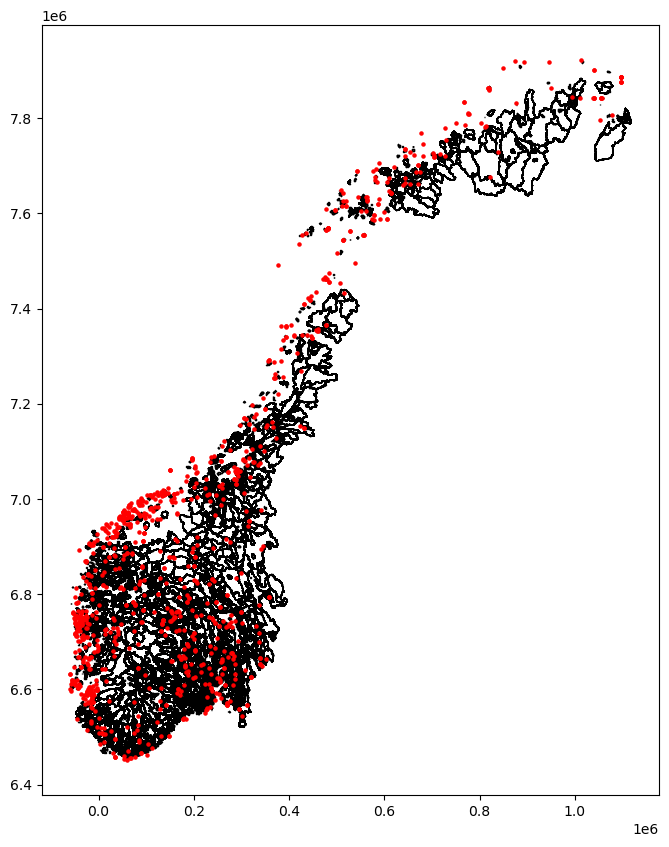

In [72]:
# Plot points and catchments
ax = cat_gdf.plot(
    facecolor="none",
    edgecolor="k",
    figsize=(10, 10),
)

pts_gdf.plot(
    ax=ax,
    color="red",
    markersize=5,
)

### Check point assignment

Plot a random catchment with all the point sources assigned to it

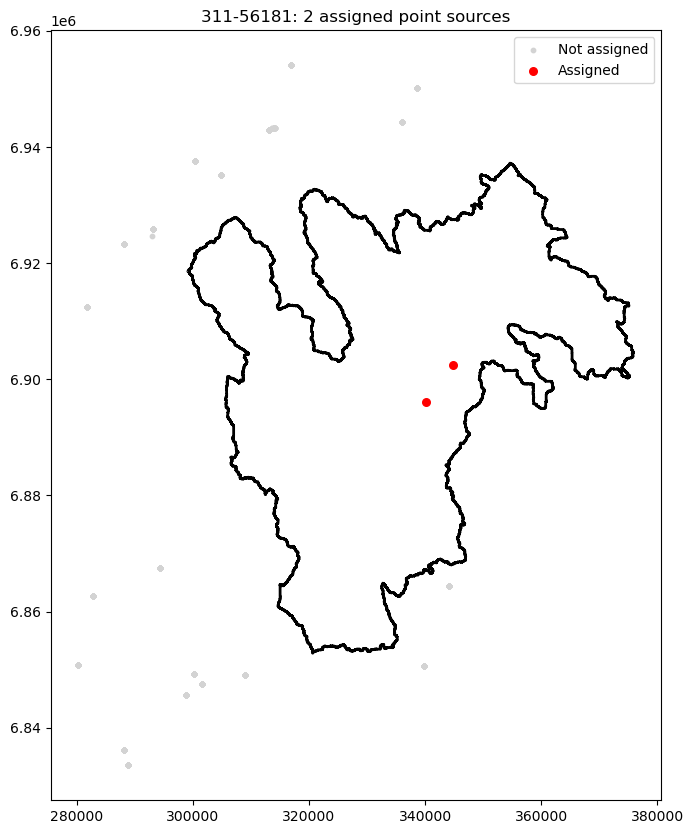

In [13]:
# Pick a random catchment
cat_id = np.random.choice(pt_loads_df[cat_id_col].unique())

# Catchment polygon
cat = cat_gdf.loc[cat_gdf[cat_id_col] == cat_id]

# Points assigned to this catchment
assigned_ids = (
    joined.loc[
        joined[cat_id_col] == cat_id,
        "pt_site_id",
    ]
    .unique()
)

assigned_pts = (
    joined.loc[joined[cat_id_col] == cat_id]
    .drop_duplicates(subset="pt_site_id")
)

# Nearby points not assigned
xmin, ymin, xmax, ymax = cat.total_bounds

buffer_dist = 20_000  # m
nearby_pts = pts_gdf.cx[
    xmin-buffer_dist:xmax+buffer_dist,
    ymin-buffer_dist:ymax+buffer_dist,
]

nearby_unassigned = nearby_pts.loc[
    ~nearby_pts["pt_site_id"].isin(assigned_ids)
]

fig, ax = plt.subplots(figsize=(10, 10))

cat.boundary.plot(
    ax=ax,
    color="black",
    linewidth=2,
)

nearby_unassigned.plot(
    ax=ax,
    color="lightgrey",
    markersize=10,
    label="Not assigned",
)

assigned_pts.plot(
    ax=ax,
    color="red",
    markersize=30,
    label="Assigned",
)

ax.legend()
ax.set_title(f"{cat_id}: {len(assigned_pts)} assigned point sources")

plt.show()

### Check number of catchments each point is assigned to

In [14]:
# How many unique catchments does each point belong to?
matches = (
    joined[
        ["pt_site_id", cat_id_col]
    ]
    .drop_duplicates()
    .groupby("pt_site_id")
    .size()
    .rename("n_catchments")
)

top_pids = matches.sort_values(ascending=False).head(20)

top_pids

pt_site_id
4620.0004.01    66
4620.0008.01    66
4620.0015.01    66
4620.0012.01    66
4620.0013.01    66
4620.0014.01    66
3330.0011.01    66
3450.0016.01    62
3330.0008.01    62
3330.0034.01    62
3330.0006.01    61
3330.0035.01    61
3330.0010.01    60
3453.0012.01    59
3328.0050.01    59
3234.0010.01    59
3330.0033.01    58
3330.0007.01    58
3330.0043.01    58
3328.0016.01    58
Name: n_catchments, dtype: int64

Plausible that one point would lie in 66 catchments?! Yes if in the headwaters of a large, well-monitored river. Checked, and the top-10 pids (i.e. points associated to most catchments) are large WWTWs that all lie within the headwaters of Drammenselva. Given how much monitoring there is of Drammenselva, this is plausible. Though clearly room to consolidate the catchment boundaries a bit...

In [15]:
pid = top_pids.index[10]

# Point location (one row only)
pid_gdf = (
    joined.loc[joined["pt_site_id"] == pid]
    .drop_duplicates(subset=["pt_site_id"])
)

pid_gdf = gpd.GeoDataFrame(
    pid_gdf,
    geometry="geometry",
    crs=cat_gdf.crs,
)

print(pid_gdf)

# Array of monitoring site codes for catchs containing the point
catches_with_pid = (
    joined.loc[joined["pt_site_id"] == pid, cat_id_col]
    .unique()
)

# Select associated geometries
cats_pid_gdf = cat_gdf.loc[cat_gdf[cat_id_col].isin(catches_with_pid)].copy()
print(pid)
print(len(cats_pid_gdf))
cats_pid_gdf.head()

        pt_site_id  outlet_x_utm33  outlet_y_utm33  year            sector  \
3253  3330.0006.01   119353.969092    6.743935e+06  2013  Large wastewater   

                   site_name     type  DIN_kg  TOTN_kg  TOTP_kg  TOC_kg  \
3253  Sudndalen avløpsanlegg  Kjemisk   433.2    601.7      5.0     NaN   

                            geometry  index_right   site_code  
3253  POINT (119353.969 6743934.605)         1848  012-101866  
3330.0006.01
61


,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2,geometry
1848,012-101866,8.430082,60.578376,101866,Hallingdalselvi - Innløp Strandafjorden,2020,2020,1.0,1,1.0,1536.500992,"POLYGON ((99580 6727140, 99620 6727140, 99620 ..."
1852,012-101870,8.178598,60.625834,101870,Storåni - Hol 1,2020,2020,1.0,1,1.0,760.387779,"POLYGON ((123740 6755740, 123740 6755720, 1237..."
1853,012-101871,8.216128,60.614872,101871,Storåni - innløp Hovsfjorden,2020,2020,1.0,1,1.0,772.143259,"POLYGON ((123740 6755740, 123740 6755720, 1237..."
1854,012-101872,8.278462,60.611542,101872,Storåni - innløp Holsfjorden,2020,2020,1.0,1,1.0,791.704988,"POLYGON ((123740 6755740, 123740 6755720, 1237..."
1884,012-103993,9.939195,59.917997,103993,Drammenselva ved Linnerud,2020,2023,3.9,24,12.0,15185.504642,"POLYGON ((234700 6784960, 234680 6784960, 2346..."


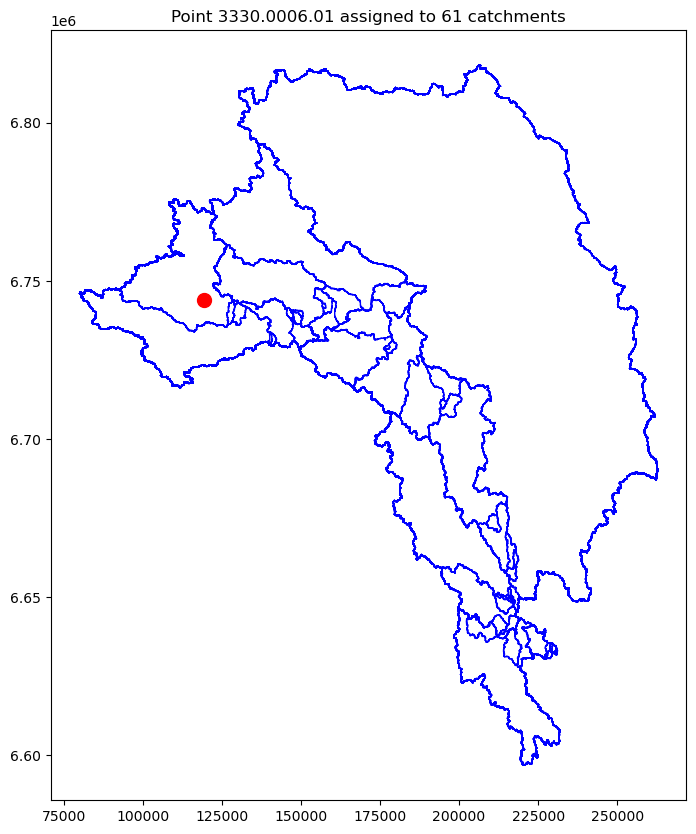

In [16]:
# Plot point and all the catchments it is assigned to

fig, ax = plt.subplots(figsize=(10, 10))

# Catchments
cats_pid_gdf.plot(
    ax=ax,
    facecolor="none",
    edgecolor="blue",
    linewidth=1,
)

# Point
pid_gdf.plot(
    ax=ax,
    color="red",
    markersize=100,
    zorder=10,
)

ax.set_title(
    f"Point {pid} assigned to {len(cats_pid_gdf)} catchments"
)

plt.show()

### Manual check of aggregation for one catchment

In [17]:
# Manual check of aggregation for one catchment
cat = pt_loads_df[cat_id_col].iloc[0]
yr = 2020
cat

'001-119928'

In [18]:
check = joined.loc[
    (joined[cat_id_col] == cat)
    & (joined["year"] == yr),
    par_list,
]#.sum()
check

,DIN_kg,TOTN_kg,TOTP_kg,TOC_kg
22898,1418.0,1575.6,7.5,290.7
22899,22621.3,25134.8,123.4,24926.8
22900,8677.2,12051.7,71.1,8103.9
22903,61.3,80.6,3.8,NaN
22904,87.5,97.2,1.0,NaN


In [19]:
pt_loads_df.loc[
    (pt_loads_df[cat_id_col] == cat)
    & (pt_loads_df["year"] == yr),
    par_list,
]

,DIN_kg,TOTN_kg,TOTP_kg,TOC_kg
7,32865.3,38939.9,206.8,33321.4


In [20]:
# Check for suspicious values
pt_loads_df[par_list].describe()

,DIN_kg,TOTN_kg,TOTP_kg,TOC_kg
count,1.775600e+04,1.775600e+04,17756.000000,1.775600e+04
mean,2.957645e+04,3.656510e+04,602.321846,4.150222e+04
std,1.397925e+05,1.734618e+05,3132.289541,3.081584e+05
min,0.000000e+00,0.000000e+00,0.000000,0.000000e+00
25%,3.050000e+02,3.591000e+02,6.700000,0.000000e+00
50%,2.011900e+03,2.328100e+03,41.000000,7.773000e+02
75%,9.481600e+03,1.112750e+04,220.975000,7.390925e+03
max,1.782156e+06,2.259812e+06,56148.600000,9.274597e+06


### Check catchments with large loads vs national totals

In [21]:
# National totals in T/yr, averaged over the full period
national_df = (pt_df.groupby("year")[par_list].sum() / 1000).mean()
national_df


DIN_kg     13145.330225
TOTN_kg    18050.102250
TOTP_kg     1219.681483
TOC_kg     31531.707783
dtype: float64

In [22]:
# Basic check. Recalculate as tonnes/yr first
(pt_loads_df[par_list] / 1000).describe()

,DIN_kg,TOTN_kg,TOTP_kg,TOC_kg
count,17756.000000,17756.000000,17756.000000,17756.000000
mean,29.576448,36.565102,0.602322,41.502220
std,139.792461,173.461822,3.132290,308.158390
min,0.000000,0.000000,0.000000,0.000000
25%,0.305000,0.359100,0.006700,0.000000
50%,2.011900,2.328100,0.041000,0.777300
75%,9.481600,11.127500,0.220975,7.390925
max,1782.155500,2259.812200,56.148600,9274.597400


In [23]:
# Where is the site with over 9000 tonnes of TOC/year?
# This site only has such high TOC in 2024, other years it's 4000 T/yr
pt_loads_df.loc[pt_loads_df['TOC_kg'] > 9000000]

,site_code,year,DIN_kg,TOTN_kg,TOTP_kg,TOC_kg
2136,002-60284,2024,1739404.2,2248302.0,46442.2,9274597.4


In [24]:
# Look at catchments with largest loads - top 10 are Glomma
site_codes = set()

for par in par_list:
    top10 = pt_loads_df.loc[pt_loads_df['year']==2024].nlargest(3, par)
    site_codes.update(top10["site_code"])
    print(par)
    print(pt_loads_df.loc[pt_loads_df['year']==2024].nlargest(3, par))

cat_gdf.loc[cat_gdf[cat_id_col].isin(site_codes)]

DIN_kg
      site_code  year     DIN_kg    TOTN_kg  TOTP_kg     TOC_kg
2136  002-60284  2024  1739404.2  2248302.0  46442.2  9274597.4
2112  002-60282  2024  1682904.2  2135302.0  38442.2  5380397.4
2124  002-60283  2024  1682904.2  2135302.0  38442.2  5380397.4
TOTN_kg
      site_code  year     DIN_kg    TOTN_kg  TOTP_kg     TOC_kg
2136  002-60284  2024  1739404.2  2248302.0  46442.2  9274597.4
2112  002-60282  2024  1682904.2  2135302.0  38442.2  5380397.4
2124  002-60283  2024  1682904.2  2135302.0  38442.2  5380397.4
TOTP_kg
      site_code  year     DIN_kg    TOTN_kg  TOTP_kg     TOC_kg
2136  002-60284  2024  1739404.2  2248302.0  46442.2  9274597.4
2112  002-60282  2024  1682904.2  2135302.0  38442.2  5380397.4
2124  002-60283  2024  1682904.2  2135302.0  38442.2  5380397.4
TOC_kg
      site_code  year     DIN_kg    TOTN_kg  TOTP_kg     TOC_kg
2136  002-60284  2024  1739404.2  2248302.0  46442.2  9274597.4
2112  002-60282  2024  1682904.2  2135302.0  38442.2  5380397.4
2124  002-

,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2,geometry
732,002-60282,11.10680,59.26375,60282,"Glomma, Borregård B1",2011,2012,1.0,4,4.0,41696.357733,"POLYGON ((224740 6795540, 224720 6795540, 2247..."
733,002-60283,11.10059,59.26805,60283,"Glomma, Borregård B2",2011,2012,1.0,4,4.0,41696.775962,"POLYGON ((224740 6795540, 224720 6795540, 2247..."
734,002-60284,11.09243,59.27077,60284,"Glomma, Borregård B3",2011,2012,1.0,4,4.0,41698.280949,"POLYGON ((233700 6784480, 233700 6784500, 2337..."


In [25]:
# Note potentially dodgy TOC value in 2024 - much higher than previous years
glomma_annual = pt_loads_df.loc[pt_loads_df['site_code'] == '002-60284']
glomma_annual

,site_code,year,DIN_kg,TOTN_kg,TOTP_kg,TOC_kg
2125,002-60284,2013,1430031.6,1876020.8,45512.7,7168258.0
2126,002-60284,2014,1430925.8,1886435.0,44174.2,6818050.3
2127,002-60284,2015,1559686.3,2014787.9,51019.7,6568829.9
2128,002-60284,2016,1656381.3,2155014.2,53429.0,6082971.3
2129,002-60284,2017,1626961.5,2102447.6,36439.9,6277017.0
2130,002-60284,2018,1678841.5,2146098.3,42481.0,5904316.1
2131,002-60284,2019,1782155.5,2259812.2,56148.6,6089908.8
2132,002-60284,2020,1750464.6,2216452.1,37086.0,5860984.9
2133,002-60284,2021,1634887.5,2064741.4,45509.8,5787048.6
2134,002-60284,2022,1642110.2,2066225.1,42533.5,5453676.2


In [26]:
# Work out Glomma loads as percent of national total

glomma_av = glomma_annual[par_list].mean() / 1000
print(glomma_av)

# Glomma as proportional of national, average for full period
print("Percent of national total:")
(glomma_av / national_df) * 100

DIN_kg     1630.819892
TOTN_kg    2090.963092
TOTP_kg      45.094800
TOC_kg     6349.136183
dtype: float64
Percent of national total:


DIN_kg     12.406078
TOTN_kg    11.584217
TOTP_kg     3.697260
TOC_kg     20.135719
dtype: float64

Averaged over the period 2013-2024, Glomma has about 11-12% of the national DIN and TotN, but a much smaller portion of the TP (4%) compared to N, and rather high TOC (20%). Plausible?

DIN vs TOTN looks reasonable (80% of totN is DIN)

### Check temporal consistency

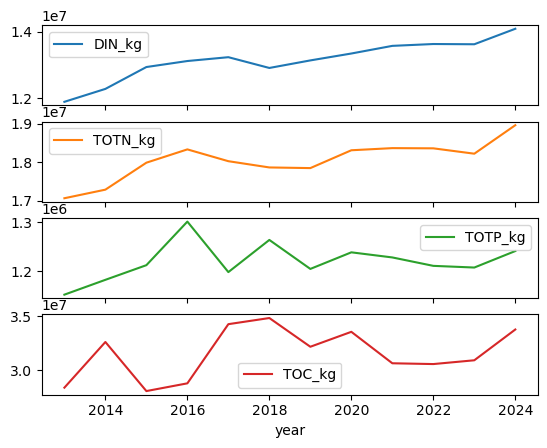

In [47]:
# Summed over all discharge points in the TEOTIL3 DB
annual = (
    pt_df.groupby("year")[par_list]
    .sum()
)

annual.plot(subplots=True)
plt.show()

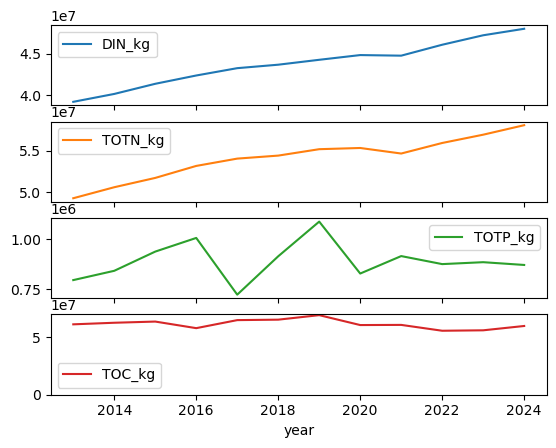

In [133]:
# Summed over all catchments in cat_gdf
annual_cats = (
    pt_loads_df.groupby("year")[par_list]
    .sum()
)

annual_cats.plot(subplots=True)
plt.show()

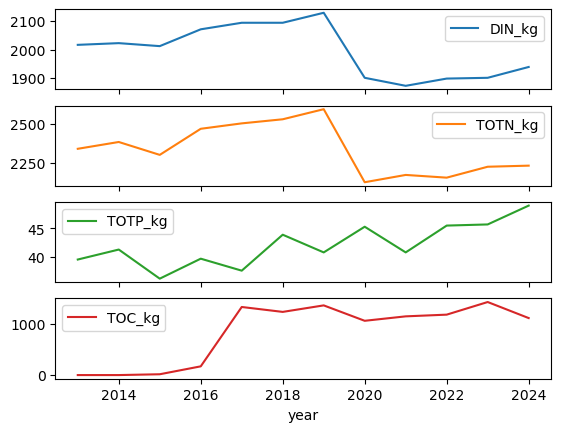

In [49]:
# Averaged over all catchments in cat_gdf
annual_cats = (
    pt_loads_df.groupby("year")[par_list]
    .median()
)

annual_cats.plot(subplots=True)
plt.show()

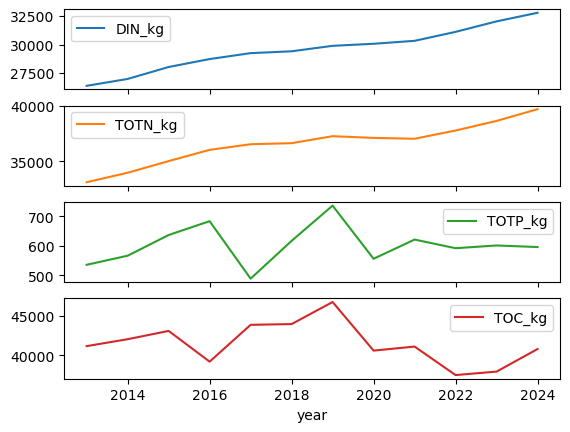

In [50]:
# Averaged over all catchments in cat_gdf
annual_cats = (
    pt_loads_df.groupby("year")[par_list]
    .mean()
)

annual_cats.plot(subplots=True)
plt.show()

In [53]:
pt_loads_df.groupby("year").apply(lambda x: (x["TOC_kg"] > 0).sum())

/tmp/ipykernel_3026/3886148731.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pt_loads_df.groupby("year").apply(lambda x: (x["TOC_kg"] > 0).sum())


year
2013     538
2014     540
2015     746
2016     813
2017    1289
2018    1337
2019    1286
2020    1338
2021    1313
2022    1355
2023    1334
2024    1291
dtype: int64

In [57]:
pt_df.groupby(["year", "sector"]).apply(lambda x: (x["TOC_kg"] > 0).sum()).reset_index()

/tmp/ipykernel_3026/2661184729.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pt_df.groupby(["year", "sector"]).apply(lambda x: (x["TOC_kg"] > 0).sum()).reset_index()


,year,sector,0
0,2013,Industry,137
1,2013,Large wastewater,160
2,2014,Industry,137
3,2014,Large wastewater,166
4,2015,Industry,135
5,2015,Large wastewater,401
6,2016,Industry,143
7,2016,Large wastewater,550
8,2017,Industry,142
9,2017,Large wastewater,2207


/tmp/ipykernel_3026/4137595568.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: (x["TOC_kg"] > 0).sum())


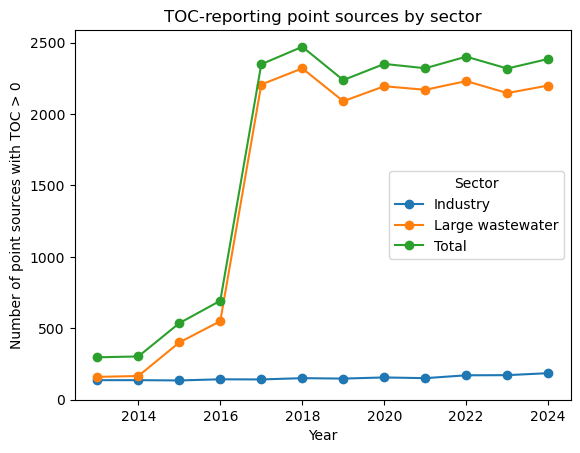

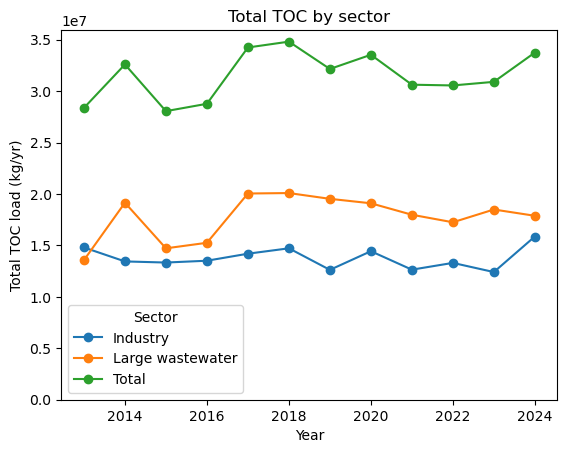

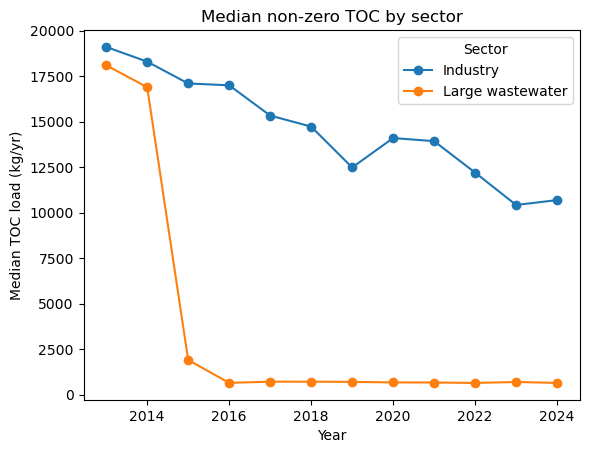

In [69]:
# Number of TOC-reporting sites, split by sector
toc_counts = (
    pt_df.groupby(["year", "sector"])
    .apply(lambda x: (x["TOC_kg"] > 0).sum())
    .unstack("sector")
)

fig, ax = plt.subplots()

toc_counts.plot(ax=ax, marker="o")

(pt_df["TOC_kg"] > 0).groupby(pt_df["year"]).sum().plot(ax=ax, marker="o", label="Total")

ax.set_xlabel("Year")
ax.set_ylabel("Number of point sources with TOC > 0")
ax.set_title("TOC-reporting point sources by sector")
ax.legend(title="Sector")
plt.ylim(ymin=0)
plt.show()

# Total TOC by sector
fig, ax = plt.subplots()

pt_df.groupby(["year", "sector"])["TOC_kg"].sum().unstack().plot(
    ax=ax,
    marker="o",
)

pt_df.groupby("year")["TOC_kg"].sum().plot(
    ax=ax,
    marker="o",
    label="Total"
)

plt.ylim(ymin=0)
ax.set_xlabel("Year")
ax.set_ylabel("Total TOC load (kg/yr)")
ax.set_title("Total TOC by sector")
ax.legend(title="Sector")
plt.show()

# Median non-zero TOC by sector
fig, ax = plt.subplots()

(
    pt_df.loc[pt_df["TOC_kg"] > 0]
    .groupby(["year", "sector"])["TOC_kg"]
    .median()
    .unstack()
    .plot(
        ax=ax,
        marker="o",
    )
)

ax.set_xlabel("Year")
ax.set_ylabel("Median TOC load (kg/yr)")
ax.set_title("Median non-zero TOC by sector")
ax.legend(title="Sector")
plt.show()

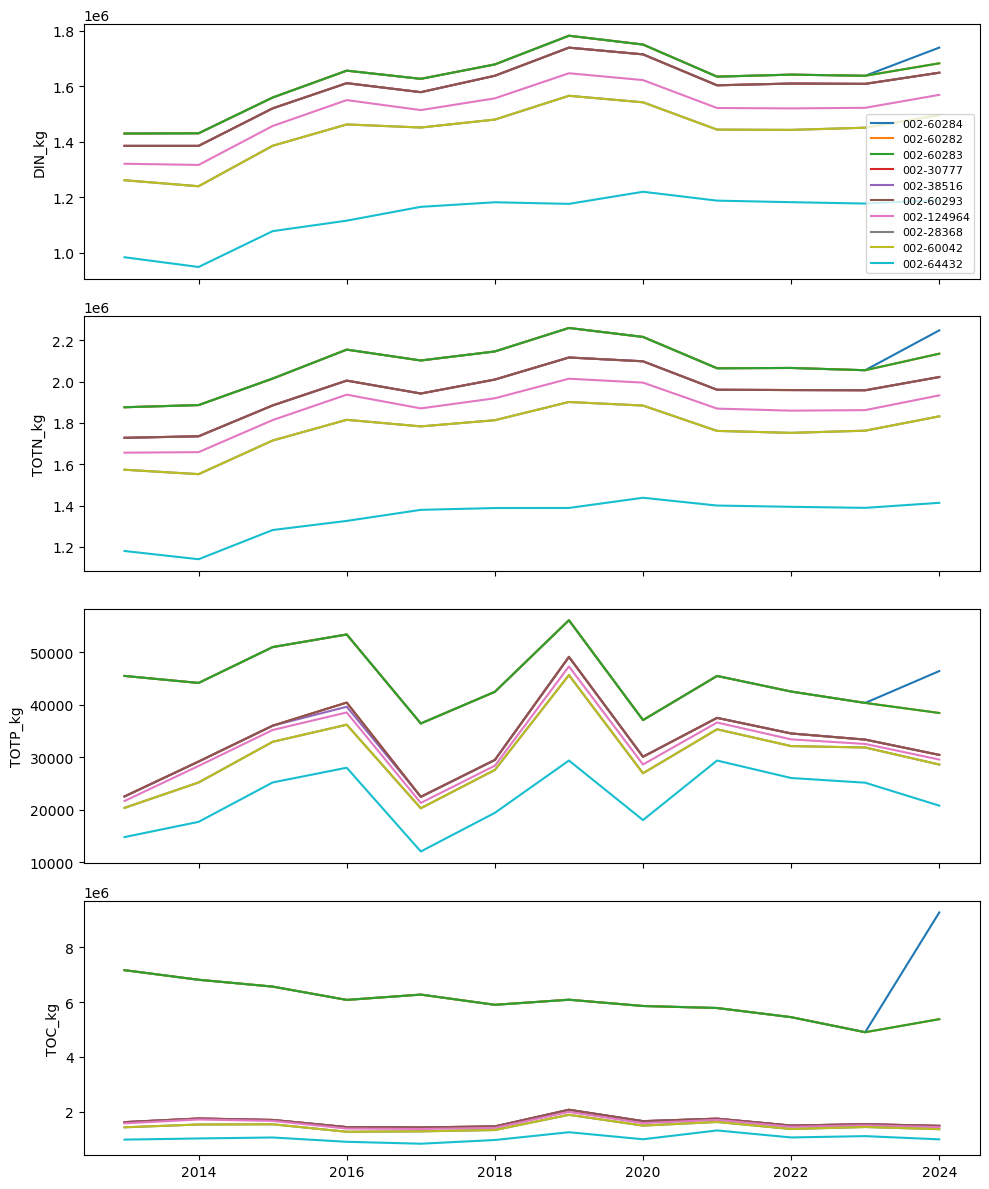

In [28]:
par = "TOC_kg"
n_catchs = 10

top_cats = (
    pt_loads_df.groupby(cat_id_col)[par]
    .mean()
    .nlargest(n_catchs)
    .index
)

fig, axes = plt.subplots(
    len(par_list),
    1,
    figsize=(10, 12),
    sharex=True,
)

for i, par in enumerate(par_list):
    ax = axes[i]

    for cat in top_cats:
        df = pt_loads_df.loc[
            pt_loads_df[cat_id_col] == cat
        ]

        ax.plot(
            df["year"],
            df[par],
            label=cat,
        )

    ax.set_ylabel(par)

axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()


In [44]:
# Should these be so overlapping? Yes, monitoring points very close together
cat_gdf.loc[cat_gdf[cat_id_col].isin(top_cats)]

,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2,geometry
310,002-124964,11.143152,59.545797,124964,Vammasjøen ved Vammeli,2024,2025,1.0,6,6.00,40542.087160,"POLYGON ((224720 6795540, 224720 6795560, 2247..."
393,002-28368,11.154680,59.637878,28368,Glomma ved Solbergfoss,2005,2025,20.9,330,15.78,40384.630818,"POLYGON ((224720 6795540, 224720 6795560, 2247..."
477,002-30777,11.128790,59.275255,30777,Glomma ved utløp Sarpsfossen (GLOU),1986,2009,23.2,485,20.87,41691.325730,"POLYGON ((224740 6795540, 224720 6795540, 2247..."
485,002-38516,11.134294,59.279465,38516,Glomma ved Sarpsfoss,1990,2024,34.7,539,15.55,41688.901865,"POLYGON ((224740 6795540, 224720 6795540, 2247..."
731,002-60042,11.138216,59.617248,60042,Glomma ved Sundgård,2017,2023,6.6,44,12.00,40396.377972,"POLYGON ((224720 6795540, 224720 6795560, 2247..."
732,002-60282,11.106800,59.263750,60282,"Glomma, Borregård B1",2011,2012,1.0,4,4.00,41696.357733,"POLYGON ((224740 6795540, 224720 6795540, 2247..."
733,002-60283,11.100590,59.268050,60283,"Glomma, Borregård B2",2011,2012,1.0,4,4.00,41696.775962,"POLYGON ((224740 6795540, 224720 6795540, 2247..."
734,002-60284,11.092430,59.270770,60284,"Glomma, Borregård B3",2011,2012,1.0,4,4.00,41698.280949,"POLYGON ((233700 6784480, 233700 6784500, 2337..."
736,002-60293,11.123060,59.270967,60293,"Glomma, Borregård",2011,2011,1.0,3,3.00,41691.863918,"POLYGON ((224740 6795540, 224720 6795540, 2247..."
859,002-64432,11.162343,59.923677,64432,Glomma ved Fetsund,2014,2026,11.6,127,10.98,38779.115197,"POLYGON ((307760 6887420, 307740 6887420, 3077..."


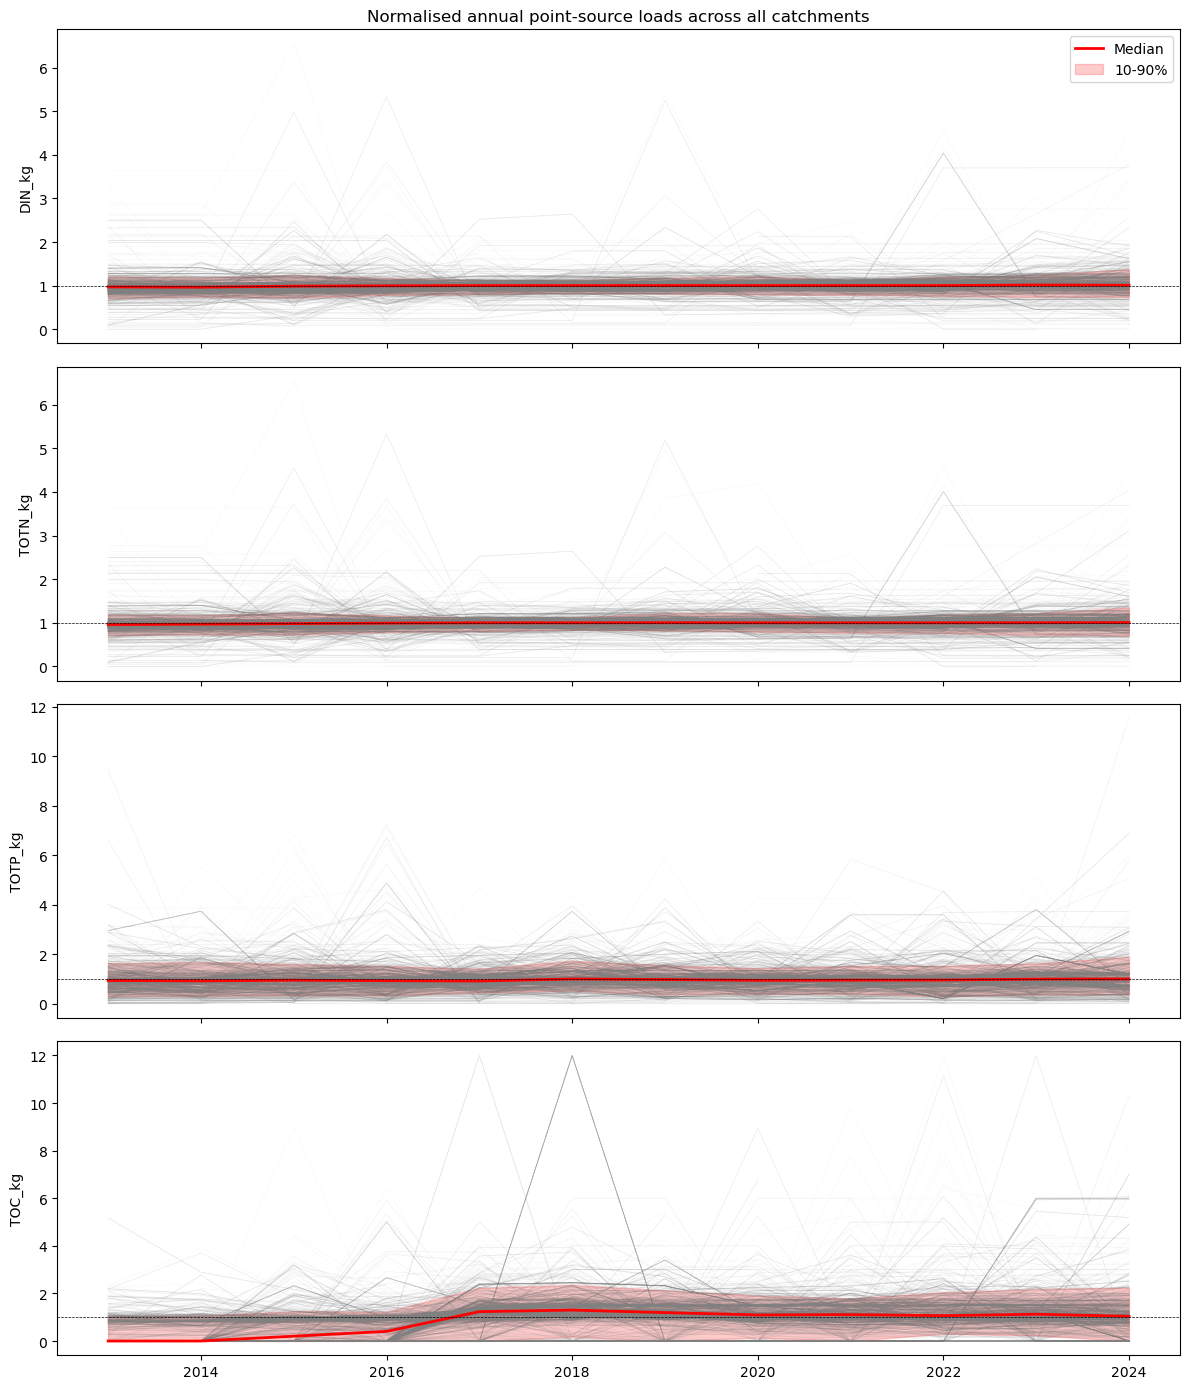

In [46]:
fig, axes = plt.subplots(
    len(par_list),
    1,
    figsize=(12, 14),
    sharex=True,
)

for ax, par in zip(axes, par_list):

    norm_li = []

    for cat, grp in pt_loads_df.groupby(cat_id_col):

        grp = grp.sort_values("year")

        # Skip empty series
        if grp[par].sum() <= 0:
            continue

        # Normalise by catchment mean
        norm = grp[par] / grp[par].mean()

        ax.plot(
            grp["year"],
            norm,
            color="grey",
            alpha=0.05,
            lw=0.5,
        )

        norm_li.append(
            pd.Series(norm.values, index=grp["year"])
        )

    norm_df = pd.concat(norm_li, axis=1)

    median = norm_df.median(axis=1)
    p10 = norm_df.quantile(0.1, axis=1)
    p90 = norm_df.quantile(0.9, axis=1)

    ax.plot(
        median.index,
        median,
        color="red",
        lw=2,
        label="Median",
    )

    ax.fill_between(
        median.index,
        p10,
        p90,
        color="red",
        alpha=0.2,
        label="10-90%",
    )

    ax.axhline(1, color="black", ls="--", lw=0.5)

    ax.set_ylabel(par)

axes[0].set_title(
    "Normalised annual point-source loads across all catchments"
)
axes[0].legend()

plt.tight_layout()
plt.show()